#### 09B · Validación del emulador final (PVAR → XGBoost → ruido)
Compara la Hs horaria observada (1985–2025) con las 100 simulaciones del 08.

- Cada simulación (1941–2026) se parte en **bloques de la misma longitud que la observación** (41 años → 2 bloques por simulación, 200 en total). Las bandas son p5–p95 entre bloques: así la variabilidad muestral es comparable a la de un registro de 41 años.
- Secciones: 1. régimen medio · 2. persistencia y autocorrelación · 3. estacionalidad (y ciclo diario) · 4. variabilidad interanual · 5. extremos · 6. resumen.
- Los estadísticos se guardan en `validacion{SUF}.pkl` para no recalcular.

In [1]:
import glob, os, pickle, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import genextreme
from scipy.signal import find_peaks

In [2]:
#### Configuración
point = "p102"
SUF = "_simple"                                     # "" = ruido completo, "_simple" = simplificado
carpeta = f"outputs/xgb_pit_{point}/emulador{SUF}"
fichero_val = f"outputs/xgb_pit_{point}/validacion{SUF}.pkl"
os.makedirs("figuras", exist_ok=True)

obs = pd.read_csv(f"inputs/waves_bulk_{point}.csv", index_col=0, parse_dates=True)["VHM0"].loc["1985":"2025"].dropna()
N_ANOS = obs.index.year.nunique()                   # longitud de cada bloque simulado
ficheros = sorted(glob.glob(f"{carpeta}/sim_*.parquet"))

U90, U99 = obs.quantile(0.90), obs.quantile(0.99)   # umbrales fijos (observados) para duraciones y temporales
Q_FINO = np.unique(np.concatenate([np.linspace(0.01, 0.99, 99), 1 - np.logspace(-2, -4.5, 26)]))
Q_TABLA = [0.5, 0.9, 0.99, 0.999]
LAGS = np.arange(0, 241)                            # hasta 10 días
T_RET = [2, 10, 50, 100]
print(f"obs: {N_ANOS} años | {len(ficheros)} simulaciones | U90 = {U90:.2f} m, U99 = {U99:.2f} m")

obs: 41 años | 100 simulaciones | U90 = 1.91 m, U99 = 3.73 m


In [3]:
#### Estilo presentación
TINTA, AZUL, NARANJA, GRIS, FONDO = "#13233A", "#2C6E91", "#C8622A", "#7A8594", "#F5F3EE"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Inter", "Arial", "DejaVu Sans"],
    "font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12, "xtick.labelsize": 10, "ytick.labelsize": 10,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA, "text.color": TINTA, "xtick.color": GRIS, "ytick.color": GRIS,
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.spines.top": False, "axes.spines.right": False,
})

def banda(ax, x, arr, color=AZUL, label="sim. p5–p95", mediana=True):
    """Banda p5–p95 (y mediana) entre bloques simulados; arr con forma (bloque, x)."""
    p5, p50, p95 = np.nanpercentile(arr, [5, 50, 95], axis=0)
    ax.fill_between(x, p5, p95, color=color, alpha=0.25, lw=0, label=label)
    if mediana:
        ax.plot(x, p50, color=color, lw=1.5, label="sim. mediana")

#### Estadísticos de un bloque (se aplica igual a la observación y a cada bloque simulado)

In [4]:
def acf(s, lags):
    """Autocorrelación de la serie horaria (con huecos como NaN)."""
    x = s.asfreq("h").values.astype("float64")
    x = x - np.nanmean(x)
    v = np.nanmean(x * x)
    return np.array([1.0 if l == 0 else np.nanmean(x[:-l] * x[l:]) / v for l in lags])

def duraciones(s, u):
    """Duración (h) de cada racha continua por encima de u."""
    sobre = np.concatenate([[0], (s.asfreq("h").values > u).astype(int), [0]])
    d = np.diff(sobre)
    return np.flatnonzero(d == -1) - np.flatnonzero(d == 1)

def gev_niveles(am):
    c, loc, sc = genextreme.fit(am)
    return {"xi": -c, **{f"Hs{T}": genextreme.isf(1 / T, c, loc, sc) for T in T_RET}}

def estadisticos(s):
    """s: Hs horaria de un bloque de N_ANOS años completos."""
    anual = s.groupby(s.index.year)
    am = anual.max().values
    picos, _ = find_peaks(s.values, height=U99, distance=72)
    media_anual = anual.mean().values
    return {
        "q": s.quantile(Q_FINO).values,
        "media": s.mean(), "std": s.std(),
        "acf": acf(s, LAGS),
        "dur90": duraciones(s, U90),
        "mes_media": s.groupby(s.index.month).mean().values,
        "mes_q90": s.groupby(s.index.month).quantile(0.90).values,
        "mes_q99": s.groupby(s.index.month).quantile(0.99).values,
        "mes_max": s.groupby([s.index.year, s.index.month]).max().groupby(level=1).mean().values,
        "hora_media": s.groupby(s.index.hour).mean().values,
        "anual_media": media_anual, "anual_q95": anual.quantile(0.95).values,
        "std_anual_media": media_anual.std(), "std_anual_q95": anual.quantile(0.95).std(),
        "ac1_anual_media": np.corrcoef(media_anual[:-1], media_anual[1:])[0, 1],
        "am": np.sort(am),
        "temporales_10a": len(picos) * 10 / s.index.year.nunique(),
        "picos": s.values[picos],
        **gev_niveles(am),
    }

In [5]:
#### Observación y bloques simulados (se guarda para no recalcular)
est_obs = estadisticos(obs)

if os.path.exists(fichero_val):
    est_sim = pickle.load(open(fichero_val, "rb"))["sim"]
    print(f"cargados {len(est_sim)} bloques de {fichero_val}")
else:
    est_sim = []
    for i, fic in enumerate(ficheros):
        t = time.time()
        hs = pd.read_parquet(fic, columns=["VHM0"])["VHM0"].astype("float64")
        anos = np.unique(hs.index.year)
        anos = anos[[hs.loc[str(a)].size >= 8700 for a in anos]]           # solo años completos
        for b in range(len(anos) // N_ANOS):
            bloque = anos[b * N_ANOS:(b + 1) * N_ANOS]
            est_sim.append(estadisticos(hs[hs.index.year.isin(bloque)]))
        print(f"sim {i:03d}: {len(anos) // N_ANOS} bloques ({time.time() - t:.0f} s)", flush=True)
    pickle.dump({"obs": est_obs, "sim": est_sim}, open(fichero_val, "wb"))

pila = lambda k: np.array([e[k] for e in est_sim])                     # (bloque, ...)
print(f"{len(est_sim)} bloques de {N_ANOS} años")

sim 000: 2 bloques (1 s)
sim 001: 2 bloques (1 s)
sim 002: 2 bloques (1 s)
sim 003: 2 bloques (1 s)
sim 004: 2 bloques (1 s)
sim 005: 2 bloques (1 s)
sim 006: 2 bloques (1 s)
sim 007: 2 bloques (1 s)
sim 008: 2 bloques (1 s)
sim 009: 2 bloques (1 s)
sim 010: 2 bloques (1 s)
sim 011: 2 bloques (1 s)
sim 012: 2 bloques (1 s)
sim 013: 2 bloques (1 s)
sim 014: 2 bloques (1 s)
sim 015: 2 bloques (1 s)
sim 016: 2 bloques (1 s)
sim 017: 2 bloques (1 s)
sim 018: 2 bloques (1 s)
sim 019: 2 bloques (1 s)
sim 020: 2 bloques (1 s)
sim 021: 2 bloques (1 s)
sim 022: 2 bloques (1 s)
sim 023: 2 bloques (1 s)
sim 024: 2 bloques (1 s)
sim 025: 2 bloques (1 s)
sim 026: 2 bloques (1 s)
sim 027: 2 bloques (1 s)
sim 028: 2 bloques (1 s)
sim 029: 2 bloques (1 s)
sim 030: 2 bloques (1 s)
sim 031: 2 bloques (1 s)
sim 032: 2 bloques (1 s)
sim 033: 2 bloques (1 s)
sim 034: 2 bloques (1 s)
sim 035: 2 bloques (1 s)
sim 036: 2 bloques (1 s)
sim 037: 2 bloques (1 s)
sim 038: 2 bloques (1 s)
sim 039: 2 bloques (1 s)


In [6]:
#### Rango percentil de la observación dentro de los bloques simulados (≈ 50 ideal; < 5 o > 95 = fuera de banda)
def rango(k, v_obs=None):
    v_obs = est_obs[k] if v_obs is None else v_obs
    return 100 * np.mean(pila(k) < v_obs)

def fila(nombre, k):
    s = pila(k); p5, p50, p95 = np.percentile(s, [5, 50, 95])
    o = est_obs[k]
    return {"métrica": nombre, "obs": o, "sim p50": p50, "sim p5": p5, "sim p95": p95,
            "sesgo %": 100 * (p50 - o) / o if o else np.nan, "en banda": p5 <= o <= p95}

#### 1. Régimen medio: distribución de la Hs horaria

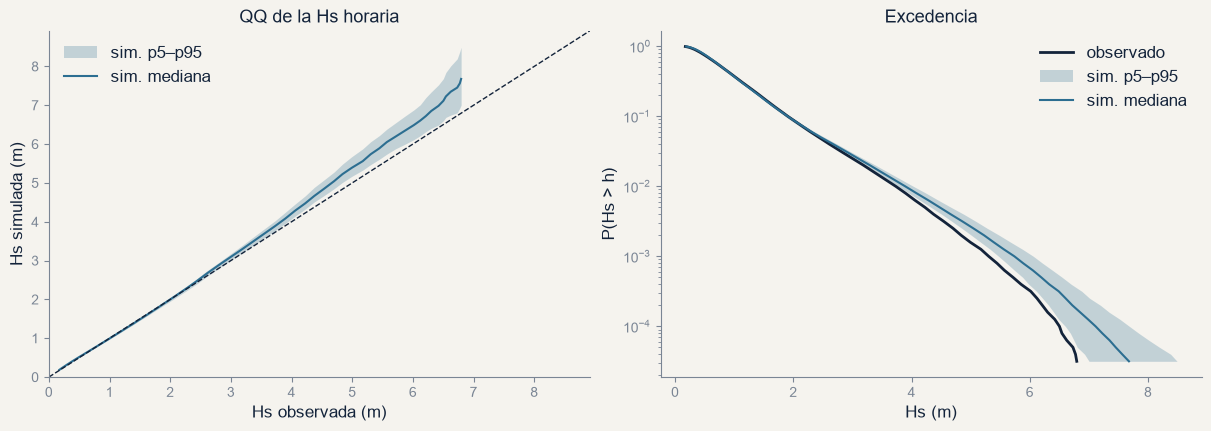

,obs,sim p50,sim p5,sim p95,sesgo %,en banda
métrica,,,,,,
media,0.998,1.009,0.993,1.024,1.117,True
std,0.731,0.750,0.729,0.770,2.638,True
q50,0.796,0.797,0.786,0.809,0.090,True
q90,1.905,1.902,1.861,1.939,-0.141,True
q99,3.731,3.891,3.770,4.028,4.292,False
q99.9,5.304,5.738,5.471,6.059,8.193,False


In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)

#### QQ: cuantiles simulados frente a observados
qs = pila("q")
p5, p50, p95 = np.percentile(qs, [5, 50, 95], axis=0)
axs[0].fill_between(est_obs["q"], p5, p95, color=AZUL, alpha=0.25, lw=0, label="sim. p5–p95")
axs[0].plot(est_obs["q"], p50, color=AZUL, lw=1.5, label="sim. mediana")
lim = [0, max(est_obs["q"].max(), p95.max()) * 1.05]
axs[0].plot(lim, lim, color=TINTA, lw=1, ls="--")
axs[0].set(xlabel="Hs observada (m)", ylabel="Hs simulada (m)", title="QQ de la Hs horaria", xlim=lim, ylim=lim)
axs[0].legend(frameon=False, loc="upper left")

#### Probabilidad de excedencia (cola en escala log)
axs[1].semilogy(est_obs["q"], 1 - Q_FINO, color=TINTA, lw=2, label="observado")
axs[1].fill_betweenx(1 - Q_FINO, p5, p95, color=AZUL, alpha=0.25, lw=0, label="sim. p5–p95")
axs[1].semilogy(p50, 1 - Q_FINO, color=AZUL, lw=1.5, label="sim. mediana")
axs[1].set(xlabel="Hs (m)", ylabel="P(Hs > h)", title="Excedencia")
axs[1].legend(frameon=False)
fig.savefig(f"figuras/val_regimen_medio{SUF}.png", dpi=200)
plt.show()

#### Tabla
filas = [fila("media", "media"), fila("std", "std")]
for j, q in enumerate(Q_TABLA):
    k = np.argmin(np.abs(Q_FINO - q))
    o = est_obs["q"][k]; s = qs[:, k]; a, m, b = np.percentile(s, [5, 50, 95])
    filas.append({"métrica": f"q{q * 100:g}", "obs": o, "sim p50": m, "sim p5": a, "sim p95": b,
                  "sesgo %": 100 * (m - o) / o, "en banda": a <= o <= b})
tabla_regimen = pd.DataFrame(filas).set_index("métrica")
tabla_regimen.round(3)

#### 2. Persistencia: autocorrelación y duración de los temporales

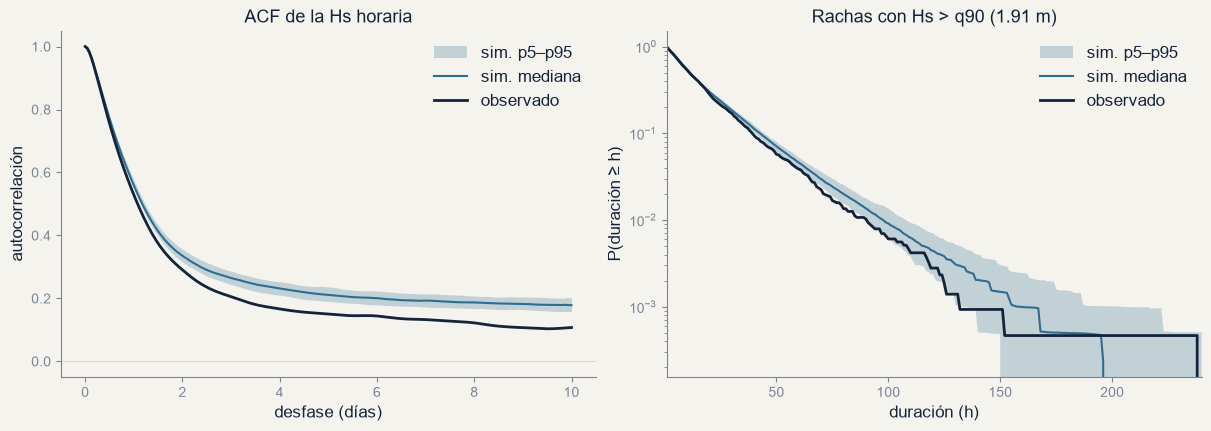

,obs,sim p50,sim p5,sim p95,en banda
métrica,,,,,
ACF 1 día,0.529,0.559,0.547,0.575,False
ACF 3 días,0.205,0.265,0.244,0.286,False
duración media > q90 (h),16.715,17.781,17.111,18.449,False


In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)

#### ACF horaria hasta 10 días
dias = LAGS / 24
banda(axs[0], dias, pila("acf"))
axs[0].plot(dias, est_obs["acf"], color=TINTA, lw=2, label="observado")
axs[0].axhline(0, color="#DDD8CE", lw=0.8)
axs[0].set(xlabel="desfase (días)", ylabel="autocorrelación", title="ACF de la Hs horaria")
axs[0].legend(frameon=False)

#### Duración de las rachas por encima de q90: función de supervivencia
d_max = 240
x = np.arange(1, d_max + 1)
superv = lambda d: np.array([(d >= h).mean() for h in x])
banda(axs[1], x, np.array([superv(e["dur90"]) for e in est_sim]))
axs[1].semilogy(x, superv(est_obs["dur90"]), color=TINTA, lw=2, label="observado")
axs[1].set(xlabel="duración (h)", ylabel="P(duración ≥ h)", title=f"Rachas con Hs > q90 ({U90:.2f} m)", xlim=(1, d_max))
axs[1].set_yscale("log")
axs[1].legend(frameon=False)
fig.savefig(f"figuras/val_persistencia{SUF}.png", dpi=200)
plt.show()

#### Resumen numérico
dur_med = np.array([e["dur90"].mean() for e in est_sim])
acf24, acf72 = pila("acf")[:, 24], pila("acf")[:, 72]
tabla_persist = pd.DataFrame([
    {"métrica": "ACF 1 día", "obs": est_obs["acf"][24], "sim p50": np.median(acf24), "sim p5": np.percentile(acf24, 5), "sim p95": np.percentile(acf24, 95)},
    {"métrica": "ACF 3 días", "obs": est_obs["acf"][72], "sim p50": np.median(acf72), "sim p5": np.percentile(acf72, 5), "sim p95": np.percentile(acf72, 95)},
    {"métrica": "duración media > q90 (h)", "obs": est_obs["dur90"].mean(), "sim p50": np.median(dur_med), "sim p5": np.percentile(dur_med, 5), "sim p95": np.percentile(dur_med, 95)},
]).set_index("métrica")
tabla_persist["en banda"] = (tabla_persist["sim p5"] <= tabla_persist["obs"]) & (tabla_persist["obs"] <= tabla_persist["sim p95"])
tabla_persist.round(3)

#### 3. Estacionalidad (y ciclo diario, que el PVAR a 6 h no tiene)

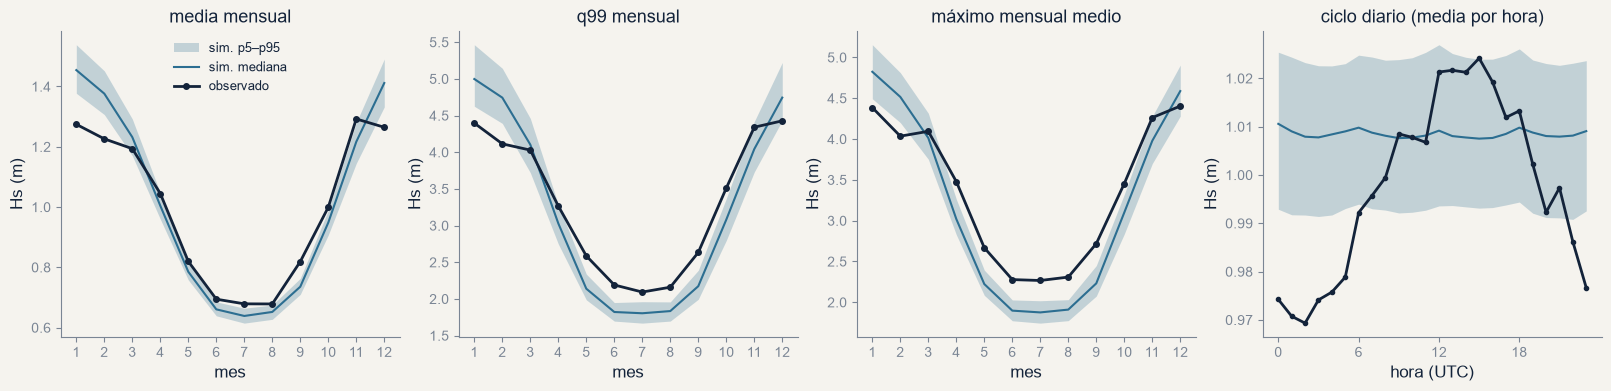

,1,2,3,4,5,6,7,8,9,10,11,12
mes_media,14.1,12.2,3.2,-3.9,-4.2,-4.9,-5.9,-3.9,-10.2,-5.1,-5.9,11.6
mes_q90,14.3,13.0,-0.9,-9.1,-9.6,-10.2,-10.8,-11.1,-15.6,-10.1,-6.3,11.3
mes_q99,13.7,15.3,1.9,-7.2,-17.3,-16.8,-13.8,-15.1,-17.5,-12.3,-6.9,7.2
mes_max,10.0,11.9,-2.0,-13.2,-16.7,-16.7,-17.2,-17.3,-17.9,-10.3,-6.7,4.2


In [9]:
meses = np.arange(1, 13)
fig, axs = plt.subplots(1, 4, figsize=(16, 3.8), constrained_layout=True)
for ax, k, tit in zip(axs[:3], ["mes_media", "mes_q99", "mes_max"],
                      ["media mensual", "q99 mensual", "máximo mensual medio"]):
    banda(ax, meses, pila(k))
    ax.plot(meses, est_obs[k], "o-", color=TINTA, lw=2, ms=4, label="observado")
    ax.set(title=tit, xlabel="mes", ylabel="Hs (m)", xticks=meses)
axs[0].legend(frameon=False, fontsize=9)

horas = np.arange(24)
banda(axs[3], horas, pila("hora_media"))
axs[3].plot(horas, est_obs["hora_media"], "o-", color=TINTA, lw=2, ms=3)
axs[3].set(title="ciclo diario (media por hora)", xlabel="hora (UTC)", ylabel="Hs (m)", xticks=[0, 6, 12, 18])
fig.savefig(f"figuras/val_estacionalidad{SUF}.png", dpi=200)
plt.show()

#### Sesgo por mes (mediana simulada − observado), en %
pd.DataFrame({k: 100 * (np.median(pila(k), 0) - est_obs[k]) / est_obs[k] for k in ["mes_media", "mes_q90", "mes_q99", "mes_max"]},
             index=meses).round(1).T

#### 4. Variabilidad interanual
Si el emulador solo tuviera variabilidad de alta frecuencia, la dispersión entre años de la media o del q95 anual quedaría por debajo de la observada.

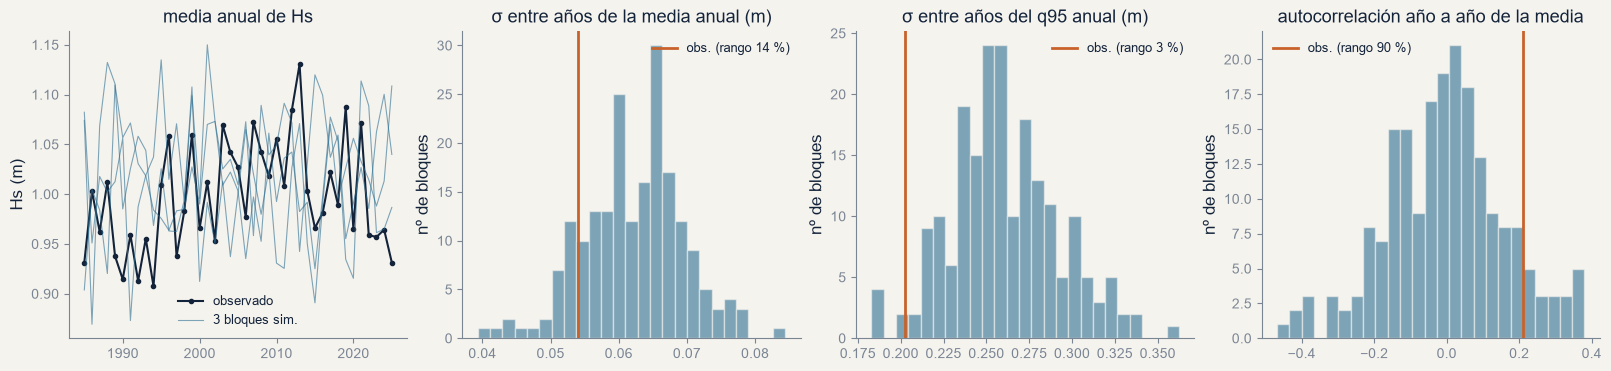

,obs,sim p50,sim p5,sim p95,sesgo %,en banda
métrica,,,,,,
σ entre años de la media anual (m),0.054,0.063,0.051,0.074,16.047,True
σ entre años del q95 anual (m),0.203,0.257,0.214,0.318,27.119,False
autocorrelación año a año de la media,0.210,-0.002,-0.276,0.286,-101.009,True


In [10]:
claves = [("std_anual_media", "σ entre años de la media anual (m)"),
          ("std_anual_q95", "σ entre años del q95 anual (m)"),
          ("ac1_anual_media", "autocorrelación año a año de la media")]
fig, axs = plt.subplots(1, 4, figsize=(16, 3.6), constrained_layout=True)

#### Serie observada de medias anuales frente a la banda de un bloque simulado cualquiera
anos_obs = np.unique(obs.index.year)
axs[0].plot(anos_obs, est_obs["anual_media"], "o-", color=TINTA, lw=1.5, ms=3, label="observado")
for j in range(3):
    axs[0].plot(anos_obs, est_sim[j]["anual_media"], color=AZUL, lw=0.8, alpha=0.6, label="3 bloques sim." if j == 0 else None)
axs[0].set(title="media anual de Hs", ylabel="Hs (m)")
axs[0].legend(frameon=False, fontsize=9)

for ax, (k, tit) in zip(axs[1:], claves):
    v = pila(k)
    ax.hist(v, bins=25, color=AZUL, alpha=0.6, edgecolor=FONDO)
    ax.axvline(est_obs[k], color=NARANJA, lw=2, label=f"obs. (rango {rango(k):.0f} %)")
    ax.set(title=tit, ylabel="nº de bloques")
    ax.legend(frameon=False, fontsize=9)
fig.savefig(f"figuras/val_interanual{SUF}.png", dpi=200)
plt.show()

tabla_interanual = pd.DataFrame([fila(t, k) for k, t in claves]).set_index("métrica")
tabla_interanual.round(3)

#### 5. Extremos: máximos anuales, niveles de retorno y temporales

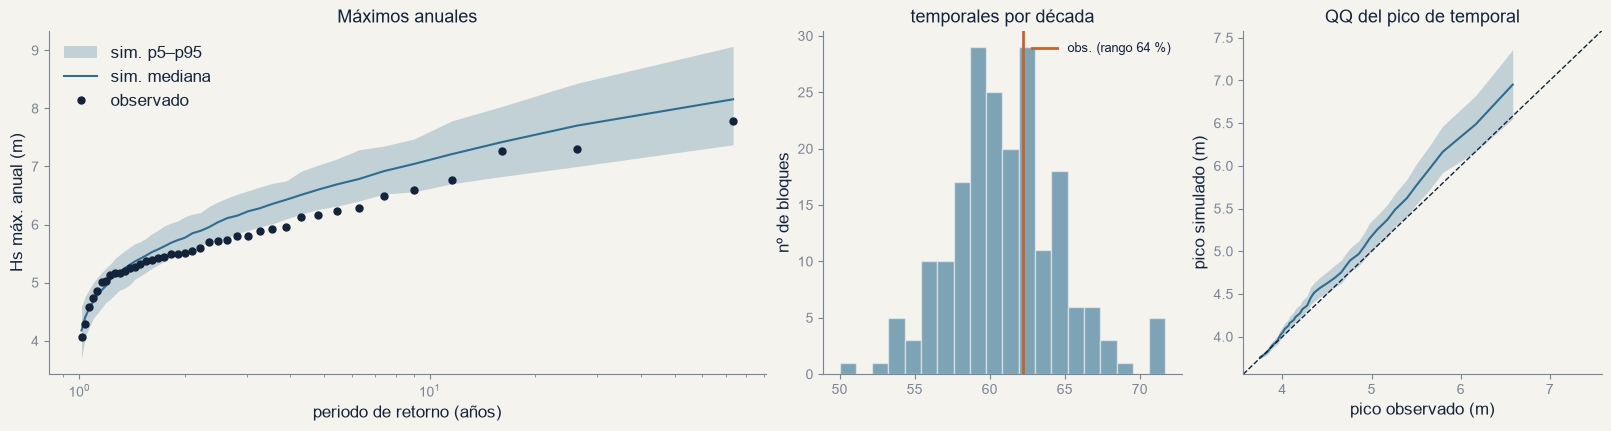

,obs,sim p50,sim p5,sim p95,sesgo %,en banda
métrica,,,,,,
xi,-0.132,-0.162,-0.365,0.015,22.460,True
Hs2,5.589,5.801,5.548,6.107,3.802,True
Hs10,6.674,7.078,6.708,7.501,6.052,False
Hs50,7.426,7.946,7.280,8.711,7.007,True
Hs100,7.698,8.259,7.461,9.285,7.290,True
temporales / 10 años,62.195,60.732,55.585,66.854,-2.353,True


In [11]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.2), constrained_layout=True, gridspec_kw={"width_ratios": [2, 1, 1]})

#### Periodo de retorno empírico (Gringorten); misma N en obs. y bloques → misma posición
n = N_ANOS
T_emp = (n + 0.12) / (np.arange(1, n + 1) - 0.44)[::-1]
banda(axs[0], T_emp, pila("am"))
axs[0].plot(T_emp, est_obs["am"], "o", color=TINTA, ms=5, label="observado")
axs[0].set_xscale("log")
axs[0].set(xlabel="periodo de retorno (años)", ylabel="Hs máx. anual (m)", title="Máximos anuales")
axs[0].legend(frameon=False)

#### Temporales por década (picos > q99 separados 72 h)
v = pila("temporales_10a")
axs[1].hist(v, bins=20, color=AZUL, alpha=0.6, edgecolor=FONDO)
axs[1].axvline(est_obs["temporales_10a"], color=NARANJA, lw=2, label=f"obs. (rango {rango('temporales_10a'):.0f} %)")
axs[1].set(title="temporales por década", ylabel="nº de bloques")
axs[1].legend(frameon=False, fontsize=9)

#### Distribución del pico de los temporales (QQ)
qq = np.linspace(0.02, 0.98, 40)
pk_o = np.quantile(est_obs["picos"], qq)
pk_s = np.array([np.quantile(e["picos"], qq) for e in est_sim])
p5, p50, p95 = np.percentile(pk_s, [5, 50, 95], axis=0)
axs[2].fill_between(pk_o, p5, p95, color=AZUL, alpha=0.25, lw=0)
axs[2].plot(pk_o, p50, color=AZUL, lw=1.5)
lim = [pk_o.min() * 0.95, max(pk_o.max(), p95.max()) * 1.03]
axs[2].plot(lim, lim, color=TINTA, ls="--", lw=1)
axs[2].set(xlabel="pico observado (m)", ylabel="pico simulado (m)", title="QQ del pico de temporal", xlim=lim, ylim=lim)
fig.savefig(f"figuras/val_extremos{SUF}.png", dpi=200)
plt.show()

#### GEV por bloque de 41 años
tabla_extremos = pd.DataFrame([fila(k, k) for k in ["xi"] + [f"Hs{T}" for T in T_RET]] +
                              [fila("temporales / 10 años", "temporales_10a")]).set_index("métrica")
tabla_extremos.round(3)

#### 6. Resumen

In [12]:
resumen = pd.concat({"régimen medio": tabla_regimen, "persistencia": tabla_persist,
                     "interanual": tabla_interanual, "extremos": tabla_extremos})
print(f"{resumen['en banda'].sum()} de {len(resumen)} métricas dentro de la banda p5–p95")
resumen.round(3)

11 de 18 métricas dentro de la banda p5–p95


obs  sim p50  sim p5  \
              métrica                                                          
régimen medio media                                   0.998    1.009   0.993   
              std                                     0.731    0.750   0.729   
              q50                                     0.796    0.797   0.786   
              q90                                     1.905    1.902   1.861   
              q99                                     3.731    3.891   3.770   
              q99.9                                   5.304    5.738   5.471   
persistencia  ACF 1 día                               0.529    0.559   0.547   
              ACF 3 días                              0.205    0.265   0.244   
              duración media > q90 (h)               16.715   17.781  17.111   
interanual    σ entre años de la media anual (m)      0.054    0.063   0.051   
              σ entre años del q95 anual (m)          0.203    0.257   0.214   
              autocorrelación año a año de la media   0.210   -0.002  -0.276   
extremos      xi                                     -0.132   -0.162  -0.365   
              Hs2                                     5.589    5.801   5.548   
              Hs10                                    6.674    7.078   6.708   
              Hs50                                    7.426    7.946   7.280   
              Hs100                                   7.698    8.259   7.461   
              temporales / 10 años                   62.195   60.732  55.585   

                                                     sim p95  sesgo %  \
              métrica                                                   
régimen medio media                                    1.024    1.117   
              std                                      0.770    2.638   
              q50                                      0.809    0.090   
              q90                                      1.939   -0.141   
              q99                                      4.028    4.292   
              q99.9                                    6.059    8.193   
persistencia  ACF 1 día                                0.575      NaN   
              ACF 3 días                               0.286      NaN   
              duración media > q90 (h)                18.449      NaN   
interanual    σ entre años de la media anual (m)       0.074   16.047   
              σ entre años del q95 anual (m)           0.318   27.119   
              autocorrelación año a año de la media    0.286 -101.009   
extremos      xi                                       0.015   22.460   
              Hs2                                      6.107    3.802   
              Hs10                                     7.501    6.052   
              Hs50                                     8.711    7.007   
              Hs100                                    9.285    7.290   
              temporales / 10 años                    66.854   -2.353   

                                                     en banda  
              métrica                                          
régimen medio media                                      True  
              std                                        True  
              q50                                        True  
              q90                                        True  
              q99                                       False  
              q99.9                                     False  
persistencia  ACF 1 día                                 False  
              ACF 3 días                                False  
              duración media > q90 (h)                  False  
interanual    σ entre años de la media anual (m)         True  
              σ entre años del q95 anual (m)            False  
              autocorrelación año a año de la media      True  
extremos      xi                                         True  
              Hs2                 